# Linear Algebra for Data Science 2026 — Lab 2, Core A
# Power iteration and inverse iteration

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after V. Kuchynskyi & R. Hryniv, 2023 </div>

## Completed by:
*   Bohdan Prokhorov
*   Markiian Yatsyshyn.

**Marked at the defence:** Core A is worth 2 points; the starred extensions at the end are one of three routes to the extension point (see the brief).

## Why this core

PageRank (Core B), the smoothing step in a graph neural network, and — later in the course — the leading principal component all need **one** eigenpair of a very large matrix that you can only *multiply by*. Power iteration is the algorithm that needs nothing more than $\mathbf{x}\mapsto A\mathbf{x}$. This core makes you implement it, **predict its speed before you run it**, find out where it breaks, and then use *inverse iteration with a shift* to reach the other eigenvalues.

**Uses:** Lecture 3.1 ($A^n = PD^nP^{-1}$, the Jordan asymptotics $n^k|\lambda|^n$, the role of $\kappa(P)$) and Lecture 3.2 (power iteration, inverse iteration). LU factorisation is a Module 0 prerequisite.

**Rules for this notebook**
* Inside `power_method` and `inverse_iteration` do **not** call `np.linalg.eig`, `np.linalg.eigvals`, `scipy.linalg.eig` or anything that calls them. You may use them elsewhere to *check* your results.
* Never call `np.linalg.inv` anywhere in this notebook. If you need $P^{-1}$ applied to something, solve a system.
* Every number you report must be reproduced by `Restart & Run All`.

In [16]:
import sys, numpy as np, scipy, scipy.linalg as sla, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.14.7 | numpy 2.5.4 | scipy 1.18.1 | matplotlib 3.11.2


### Two provided helpers

`sin_angle(u, v)` measures how far apart two *directions* are. It ignores length and sign (and, for complex vectors, any unimodular factor), so it is the right error measure for an eigenvector.

`similar_matrix(eigvals, P)` returns $A = P\,\mathrm{diag}(\text{eigvals})\,P^{-1}$ **without** forming $P^{-1}$: from $AP = PD$ we get $P^\top A^\top = (PD)^\top$, which is one linear solve.

In [17]:
def sin_angle(u, v):
    # sine of the angle between span{u} and span{v}; accurate for small angles
    u = u / np.linalg.norm(u)
    v = v / np.linalg.norm(v)
    return np.linalg.norm(u - v * np.vdot(v, u))

def similar_matrix(eigvals, P):
    # A = P diag(eigvals) P^{-1}, computed by one solve instead of an inverse
    PD = P * np.asarray(eigvals)[None, :]          # scales column j of P by eigvals[j]
    return np.linalg.solve(P.T, PD.T).T

def random_orthogonal(n):
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))                  # sign fix: a uniformly random orthogonal Q

---
## 1. Power iteration

### 1.1 The idea, recalled
Let $A$ be a diagonalisable $k\times k$ matrix with eigenvalues ordered so that $|\lambda_1| > |\lambda_2| \ge \dots \ge |\lambda_k|$ (so $\lambda_1$ is real and simple when $A$ is real) and eigenvectors $\mathbf{v}_1,\dots,\mathbf{v}_k$. Write $\mathbf{x}_0 = c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k$ with $c_1 \ne 0$. Then
$$
A^n\mathbf{x}_0 = \lambda_1^n\Bigl[c_1\mathbf{v}_1 + c_2\Bigl(\tfrac{\lambda_2}{\lambda_1}\Bigr)^n\mathbf{v}_2 + \dots + c_k\Bigl(\tfrac{\lambda_k}{\lambda_1}\Bigr)^n\mathbf{v}_k\Bigr],
$$
so the direction of $A^n\mathbf{x}_0$ approaches $\mathrm{span}\{\mathbf{v}_1\}$, and the error shrinks by roughly $|\lambda_2/\lambda_1|$ per step. Normalising at each step avoids overflow:
$$
\mathbf{x}_n := \frac{A\mathbf{x}_{n-1}}{\|A\mathbf{x}_{n-1}\|}, \qquad \lambda_1 \approx \mu_n := \mathbf{x}_n^{*} A\,\mathbf{x}_n \quad(\text{the Rayleigh quotient}).
$$

**When to stop.** Do *not* stop when $\|\mathbf{x}_n - \mathbf{x}_{n-1}\|$ is small: if $\lambda_1 < 0$, the vector flips sign at every step and never settles, although its *direction* has converged. Stop instead when the **residual** is small,
$$
\|A\mathbf{x}_n - \mu_n\mathbf{x}_n\| \le \texttt{tol}\cdot\|A\|_F .
$$
(Scaling by $\|A\|_F$, computed once, makes the test independent of units. Do not divide by $\|A\mathbf{x}_n\|$ instead: that breaks down when the eigenvalue you are after is $0$.)
A small residual says that $(\mu_n, \mathbf{x}_n)$ is an exact eigenpair of a matrix very close to $A$ — the most you can ask of any floating-point method.

### 1.2 Implement `power_method`
Return the eigenvalue estimate, the unit eigenvector estimate and a history: the Rayleigh quotients and the residuals at every step. Use `np.vdot` for $\mathbf{x}^*\mathbf{y}$ so that complex input also works.

In [18]:
def power_method(A, x0=None, tol=1e-10, max_iter=1000):
    '''
    Dominant eigenpair of A by power iteration.

    Args:
        A        : (k, k) array
        x0       : starting vector; random (from `rng`) if None
        tol      : stop when ||A x - mu x|| <= tol * ||A||_F
        max_iter : maximum number of matrix-vector products
    Returns:
        mu   : eigenvalue estimate (Rayleigh quotient)
        x    : unit eigenvector estimate
        hist : dict with arrays 'mu' and 'res', one entry per iteration
    '''
    hist = {'mu': [], 'res': []}

    if x0 is None:
        x0 = rng.random(A.shape[0])
    x = x0 / np.linalg.norm(x0)

    Af = np.linalg.norm(A)

    for _ in range(max_iter):
        prod = A @ x
        mu = np.vdot(x, prod)
        res = np.linalg.norm(prod - mu * x)

        hist['mu'].append(mu)
        hist['res'].append(res)

        if res <= tol * Af:
            break

        x = prod / np.linalg.norm(prod)

    return mu, x, {k: np.asarray(v) for k, v in hist.items()}

### 1.3 Test it
The checker compares with `np.linalg.eig`. Its tolerances are matched to `tol`: a residual of $10^{-10}$ cannot give 15 correct digits, so do not tighten them.

The test matrices are chosen on purpose: `A1` has a **negative** dominant eigenvalue, `A2` is symmetric and indefinite, `A3` is non-symmetric with prescribed real eigenvalues.

In [19]:
def check_dominant(A, mu, x, rtol=1e-6):
    lam, V = np.linalg.eig(A)
    i = np.argmax(np.abs(lam))
    assert abs(mu - lam[i]) <= rtol * abs(lam[i]), f'eigenvalue {mu} vs {lam[i]}'
    assert sin_angle(x, V[:, i]) <= rtol, f'eigenvector off by sin(angle) = {sin_angle(x, V[:, i]):.1e}'
    print(f'passed: mu = {complex(mu).real:+.10f}')

A1 = np.array([[0., 1.], [-2., -3.]])
M = rng.standard_normal((6, 6)); A2 = M + M.T
A3 = similar_matrix([-5., 3., 2., 1., 0.5], rng.standard_normal((5, 5)))
for A in (A1, A2, A3):
    mu, x, hist = power_method(A)
    check_dominant(A, mu, x)
    print('   iterations:', len(hist['res']))

passed: mu = -2.0000000006
   iterations: 31
passed: mu = -5.0027417669
   iterations: 170
passed: mu = -5.0000000004
   iterations: 56


**Question 1.3.** Last year's tests used matrices `10*np.random.rand(n, n)`. Explain why even a buggy implementation that cannot cope with a negative dominant eigenvalue would pass all of those tests. *(Hint: the entries are positive; Lecture 3.2, Perron–Frobenius.)*

---
Every element of `10*np.random.rand(10, 10)` is positive, so by Perron–Frobenius λ1 = ρ(A) is an eigenvalue, simple, and every other eigenvalue has |λj| < λ1; So the case where λ1 < 0 was never tested.

---

### 1.4 Predict the speed, then measure it

This is the main experiment of the core. Take $k = 50$, an orthogonal $Q$, and
$$
A_r = Q\,\mathrm{diag}(1,\ r,\ \text{48 values spread evenly in } [-0.3r, 0.3r])\,Q^\top, \qquad r \in \{0.5,\ 0.9,\ 0.99\}.
$$
The dominant eigenvector is $\mathbf{v}_1 = \mathbf{q}_1$, the first column of $Q$.

**(a) Predict first.** For each $r$, how many iterations should it take for $\sin\angle(\mathbf{x}_n, \mathbf{v}_1)$ to fall from about $1$ to $10^{-8}$? Write the formula and the three numbers *before* running anything.

---
Using the power method, the error decreases at the rate

$$
\sin\angle(\mathbf{x}_n,\mathbf{v}_1)\approx C\left|\frac{\lambda_2}{\lambda_1}\right|^{n}
$$

At $n=0$ this gives $\sin\angle(\mathbf{x}_0,\mathbf{v}_1)\approx C$. The starting vector is far from $\mathbf{v}_1$, so this initial sine is about $1$, and we can take $C\approx 1$ and drop it from the estimate.

We want the error to reach $10^{-8}$, so we replace the sine with it:

$$
10^{-8}\approx \left|\frac{\lambda_2}{\lambda_1}\right|^{n}
$$

and solve for $n$:

$$
n\approx\log_{\left|\lambda_2/\lambda_1\right|}10^{-8}
$$


For $\lambda_1=1$ and $\lambda_2=r$ the ratio is simply $r$, so

| $r$ | predicted $n$ |
|---|---|
| $0.5$ | $\approx 26.6\to 27$ |
| $0.9$ | $\approx 174.8\to 175$ |
| $0.99$ | $\approx 1832.9\to 1833$ |

The closer $r$ is to $1$, the slower the convergence: going from $r=0.9$ to $r=0.99$ multiplies the iteration count by about $10$.

P.S. Because $\mathbf{x}_0$ is random (not truly random, since we set a seed at the start, but let's ignore that here), the ratio $c_2/c_1$ is never exactly one. That is why the measured number of iterations differs slightly from the prediction on the plots.

---

**(b) Measure.** Write `power_errors(A, v1, lam1, n_steps, x0)` that runs exactly `n_steps` normalised iterations from `x0` and returns two arrays: the eigenvector error $\sin\angle(\mathbf{x}_n,\mathbf{v}_1)$ and the eigenvalue error $|\mu_n - \lambda_1|$. Plot both against $n$ on a log scale for the three values of $r$, with the reference lines $r^n$. Use the **same** `x0` for all runs. Report the measured iteration counts next to your predictions.

r=0.5: predicted 27, measured 26
r=0.9: predicted 175, measured 166
r=0.99: predicted 1833, measured 1734


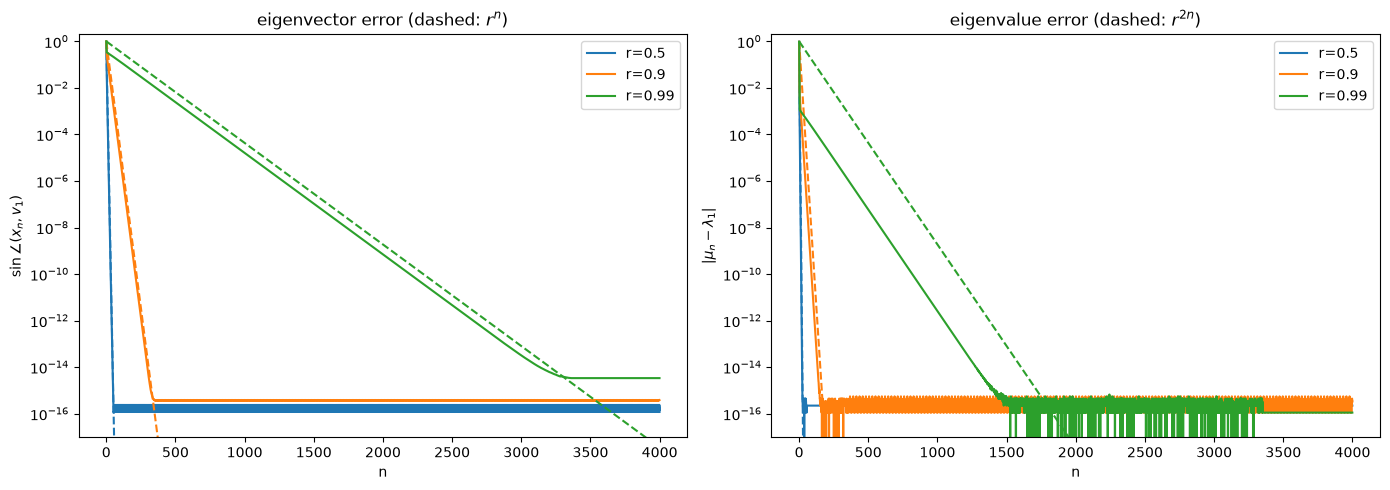

In [20]:
def power_errors(A, v1, lam1, n_steps, x0):
    x = x0 / np.linalg.norm(x0)
    sin_err, lam_err = [], []
    for i in range(n_steps):
        prod = A @ x # this multiplication and ->
        sin_err.append(float(sin_angle(x, v1)))
        lam_err.append(float(abs(x @ prod - lam1)))
        x = prod / np.linalg.norm(prod) # -> this divition is mostly why we can't reach the lower bound of float on plots with increasing of r, 
                                        # because for bigger r we need more steps and more often iterate and lose our significant numbers

        # if i == 1000:
        #     print(x)
    return sin_err, lam_err


k = 50
Q = random_orthogonal(k)
x0 = rng.standard_normal(k)
v1 = Q[:, 0]
n_steps = 4000

results = {}
for r in (0.5, 0.9, 0.99):
    d = np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, k - 2)))
    results[r] = power_errors((Q * d) @ Q.T, v1, 1.0, n_steps, x0) # because all lambdas on diagonal from 2nd to 5th dissappear quickly on first itereations, 
                                                                   # we have fast drop of green line on start (on other it also exist, but it's harder to see it)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for r, (s_err, l_err) in results.items():
    c = ax1.semilogy(s_err, label=f'r={r}')[0].get_color()
    ax1.semilogy([r ** i for i in range(n_steps)], '--', color=c)
    ax2.semilogy(l_err, color=c, label=f'r={r}')
    ax2.semilogy([r ** (2 * i) for i in range(n_steps)], '--', color=c)
    hit = next(i for i, e in enumerate(s_err) if e <= 1e-8)
    print(f'r={r}: predicted {np.ceil(np.emath.logn(r, 1e-8)):.0f}, measured {hit}')
ax1.set(xlabel='n', ylabel=r'$\sin\angle(x_n, v_1)$', title='eigenvector error (dashed: $r^n$)', ylim=(1e-17, 2))
ax2.set(xlabel='n', ylabel=r'$|\mu_n - \lambda_1|$', title='eigenvalue error (dashed: $r^{2n}$)', ylim=(1e-17, 2))
ax1.legend()
ax2.legend()
plt.tight_layout()
plt.show()

**(c) Two observations to explain.**
1. For this symmetric $A_r$ the eigenvalue error falls like $r^{2n}$ — twice as fast as the eigenvector error. You do not need to prove this (Module 4 will), but describe what you see and say why it is good news for PageRank-style uses.
2. Now repeat (b) for $r = 0.9$ only, with $A = P\,\mathrm{diag}(\dots)\,P^{-1}$ built by `similar_matrix`, where $P = U\,\mathrm{diag}(s)\,V^\top$ has orthogonal $U, V$ and singular values $s$ spread logarithmically from $1$ to $10^{-3}$, so that $\kappa(P) = 10^3$. Did the **rate** change? Did anything else change? Relate this to the role of $\kappa(P)$ in Lecture 3.1.

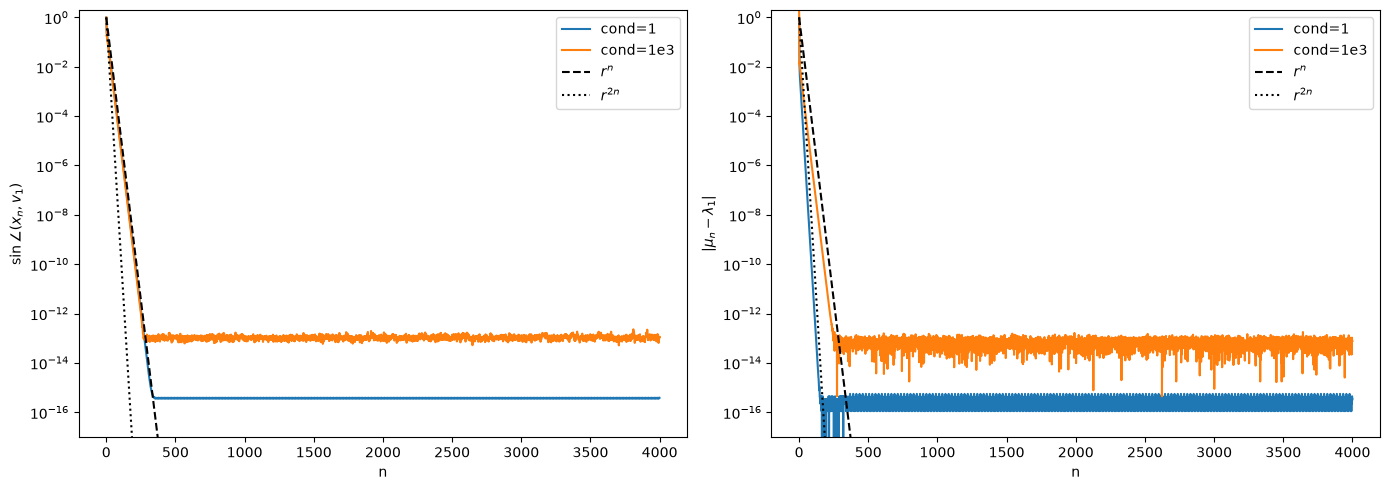

In [21]:
r = 0.9
d = np.concatenate(([1.0, r], np.linspace(-0.3 * r, 0.3 * r, k - 2)))
U, V = random_orthogonal(k), random_orthogonal(k)
P = (U * np.logspace(0, -3, k)) @ V.T
p1 = P[:, 0] / np.linalg.norm(P[:, 0])
errs = {'cond=1': results[r], 'cond=1e3': power_errors(similar_matrix(d, P), p1, 1.0, n_steps, x0)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, j, name in zip(axes, (0, 1), (r'$\sin\angle(x_n, v_1)$', r'$|\mu_n - \lambda_1|$')):
    for label, e in errs.items():
        ax.semilogy(e[j], label=label)
    ax.semilogy([r ** i for i in range(n_steps)], 'k--', label='$r^n$')
    ax.semilogy([r ** (2 * i) for i in range(n_steps)], 'k:', label='$r^{2n}$')
    ax.set(xlabel='n', ylabel=name, ylim=(1e-17, 2))
    ax.legend()
plt.tight_layout()
plt.show()

---
1. We see that eigenvalue error decreases two times faster (~1600 vs ~3200). This may not be good news for the PageRank task itself, because for that matrix we already know $\lambda_1=1$ and are interested in the eigenvector. In most other cases, however, we do not know the eigenvalue. If we are interested only in the eigenvalue (not the eigenvector), we can obtain it about twice as fast. 

2. In the cond=1000 case the error does not drop below 10⁻¹³ because np.linalg.solve builds A with only about 13 correct significant digits (the rounding error ~10⁻¹⁶ is amplified by κ(P) = 10³). The power method therefore converges to the eigenvector of this slightly perturbed matrix, and the measured error cannot go below its distance from the reference p1, which is ~10⁻¹³. We also see that the eigenvalue error lost its 2x speed advantage (it no longer falls like r^2n). This is because A is no longer symmetric (not normal), so the Rayleigh quotient error is no longer quadratic in the eigenvector error.

### 1.5 Reasons to fail
For each case below: explain *why* the method fails or slows down, give your own $3\times 3$ example, run `power_method` on it, and describe what you see (no convergence? convergence to the wrong thing? very slow convergence?). Look at `hist['res']` and `hist['mu']`, not only at the final output.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.
2. $\lambda_1 = -\lambda_2$ (two real eigenvalues of equal modulus).
3. The dominant eigenvalue is defective: a Jordan block. *Hint:* it does converge — at what rate? Compare with the asymptotics $n^k|\lambda|^n$ from Lecture 3.1. Plot the eigenvector error, the eigenvalue error and the residual against $n$; they do **not** fall at the same rate. What does that tell you about trusting a small residual?
4. The starting vector has $c_1 = 0$. First run `power_method` with its defaults on $A = Q\,\mathrm{diag}(2,1,0.5)\,Q^\top$ (random orthogonal $Q$) and $\mathbf{x}_0 = \mathbf{q}_2$: why does it stop at once, and with what answer? Then switch the stopping test off (`tol=0`, `max_iter=120`) and compare two runs: $A = \mathrm{diag}(2, 1, 0.5)$ with $\mathbf{x}_0 = \mathbf{e}_2$, and $QDQ^\top$ with $\mathbf{x}_0 = \mathbf{q}_2$. They behave differently. Explain why, and predict roughly how many iterations the second one needs before it "notices" $\mathbf{v}_1$.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.


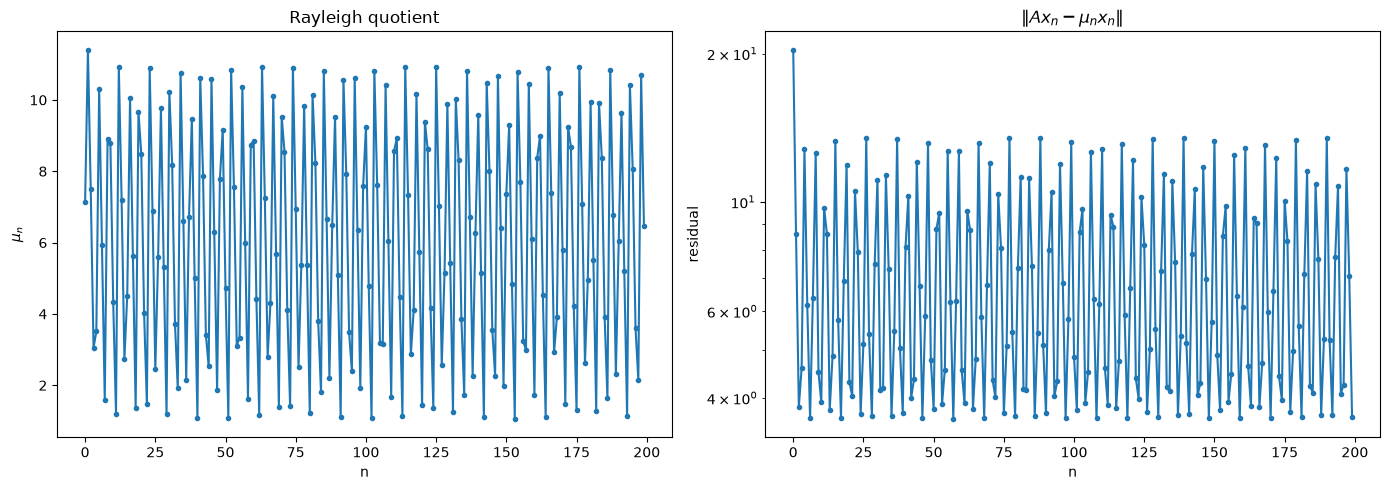


eigenvalues: [6.+7.j 6.-7.j 1.+0.j]
mu: 6.4683948307274965
x: [-0.56465825 -0.82111549  0.08324906]

2. lambda_1 = -lambda_2 (two real eigenvalues of equal modulus).


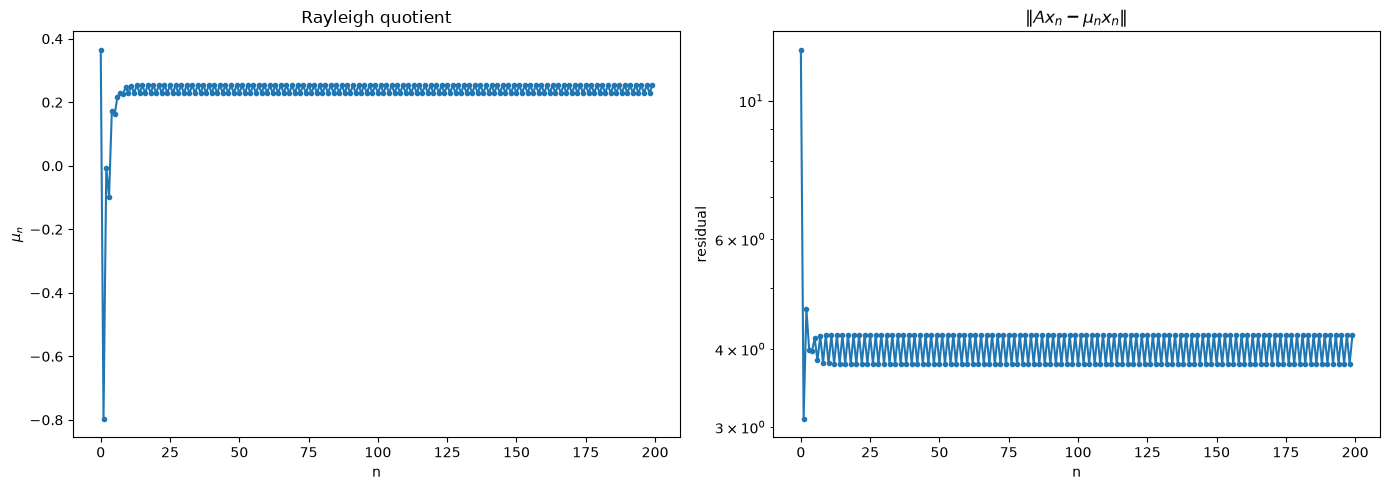


eigenvalues: [-4.+0.j  2.+0.j  4.+0.j]
mu: 0.2540437563944665
x: [0.472362   0.85830729 0.20045631]

3. Defective dominant eigenvalue (Jordan block)


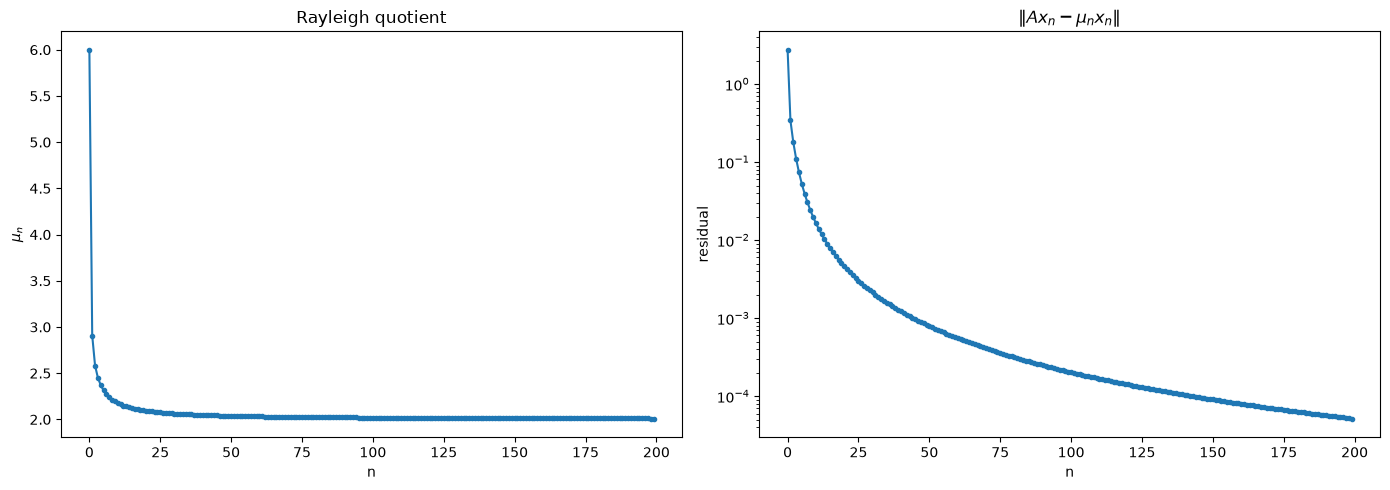


eigenvalues: [0.335     +0.j 2.00000004+0.j 1.99999996+0.j]
mu: 2.009990153971622
x: [ 0.6045432   0.61241463 -0.50938771]



In [22]:
def plot_history(A, max_iter=200, tol=1e-10, x0=None):
    single = isinstance(A, np.ndarray) and A.ndim == 2
    As = [A] if single else list(A)
    x0s = x0 if isinstance(x0, list) else [x0] * len(As)
    _, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    out = []
    for i, (Ai, x0i) in enumerate(zip(As, x0s)):
        mu, x, hist = power_method(Ai, x0=x0i, tol=tol, max_iter=max_iter)
        ax1.plot(hist['mu'].real, '.-', label=f'#{i}')
        ax2.semilogy(np.maximum(hist['res'], 1e-18), '.-', label=f'#{i}')
        out.append((mu, x, hist))
    ax1.set(xlabel='n', ylabel=r'$\mu_n$', title='Rayleigh quotient')
    ax2.set(xlabel='n', ylabel='residual', title=r'$\|Ax_n - \mu_n x_n\|$')
    if not single:
        ax1.legend()
        ax2.legend()
    plt.tight_layout()
    plt.show()
    return out[0] if single else out

P = rng.standard_normal((3, 3))

print("1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.")
D = np.array([[6., -7., 0.],
              [7.,  6., 0.],
              [0.,  0., 1.]])
A_1 = np.linalg.solve(P.T, (P @ D).T).T
mu_1, x_1, _ = plot_history(A_1)
print(f"""
eigenvalues: {np.linalg.eigvals(A_1)}
mu: {mu_1}
x: {x_1}
""")


print("2. lambda_1 = -lambda_2 (two real eigenvalues of equal modulus).")
A_2 = similar_matrix([-4., 4., 2.], P)
mu_2, x_2, _ = plot_history(A_2)
print(f"""
eigenvalues: {np.linalg.eigvals(A_2)}
mu: {mu_2}
x: {x_2}
""")

print("3. Defective dominant eigenvalue (Jordan block)")
J = np.array([[2., 1., 0.],
              [0., 2., 0.],
              [0., 0., 0.67 / 2]])

A_3 = np.linalg.solve(P.T, (P @ J).T).T
mu_3, x_3, _ = plot_history(A_3)
print(f"""
eigenvalues: {np.linalg.eigvals(A_3)}
mu: {mu_3}
x: {x_3}
""")

4. The starting vector has c_1 = 0


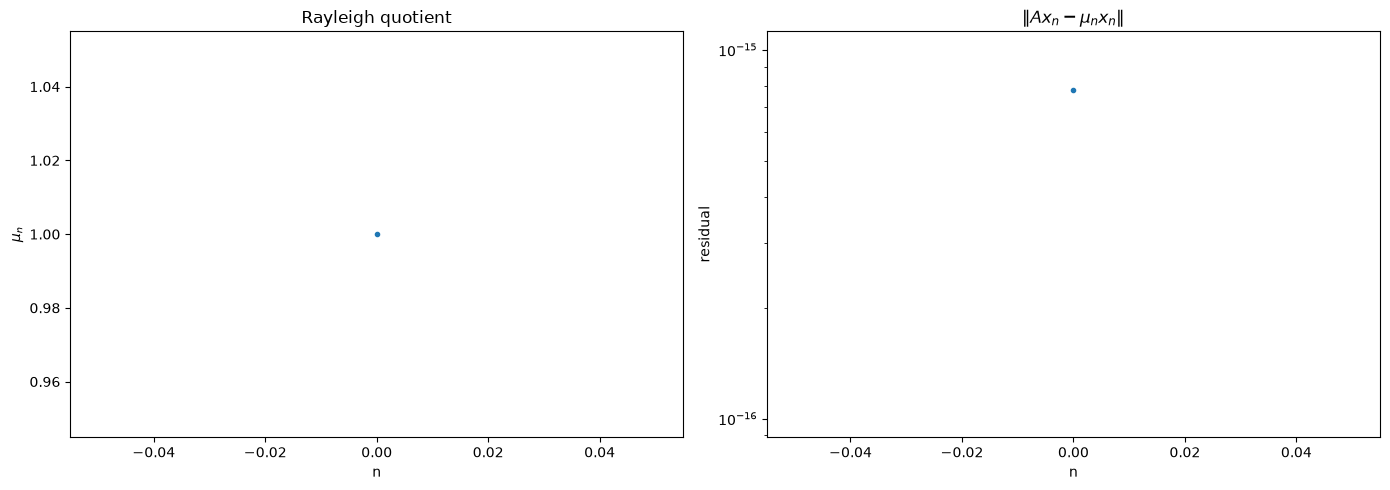

default run
iterations: 1
mu: 0.9999999999999996
sin_angle(x, q2): 2.3e-16



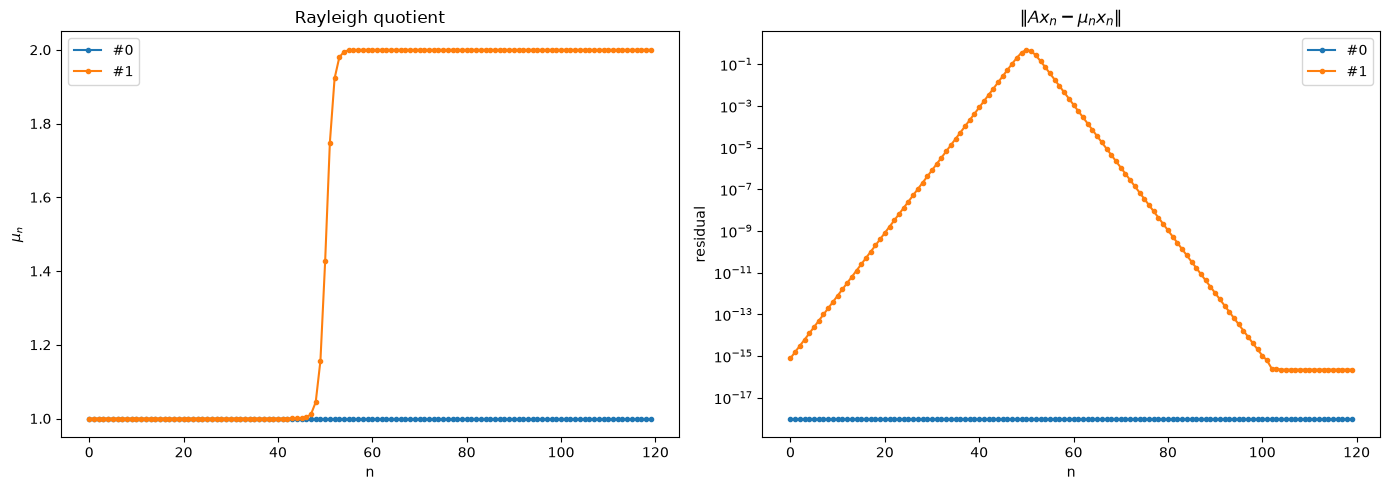

diag, x0=e2 : mu_n stays 1.0, max residual 0.0e+00
QDQ^T, x0=q2: mu_n jumps from 1 to 2 at n = 51, final mu = 2.000000
predicted n ~ log2(1/eps) = 52



In [23]:
print("4. The starting vector has c_1 = 0")
Q3 = random_orthogonal(3)
D3 = np.array([2., 1., 0.5])
A_4 = (Q3 * D3) @ Q3.T
q2 = Q3[:, 1]

mu_4, x_4, hist_4 = plot_history(A_4, x0=q2)
print(f"""default run
iterations: {len(hist_4['res'])}
mu: {mu_4}
sin_angle(x, q2): {sin_angle(x_4, q2):.1e}
""")

e2 = np.array([0., 1., 0.])
(mu_a, _, h_a), (mu_b, _, h_b) = plot_history([np.diag(D3), A_4], max_iter=120, tol=-1, x0=[e2, q2])
jump = int(np.argmax(np.abs(h_b['mu'] - 1) > 0.5))
print(f"""diag, x0=e2 : mu_n stays {h_a['mu'][-1].real:.1f}, max residual {h_a['res'].max():.1e}
QDQ^T, x0=q2: mu_n jumps from 1 to 2 at n = {jump}, final mu = {mu_b.real:.6f}
predicted n ~ log2(1/eps) = {np.log2(1 / np.finfo(float).eps):.0f}
""")

---

1. The dominant eigenvalues are the complex pair 6 ± 7i with |lambda1| = |lambda2|, so the ratio |lambda2/lambda1| = 1 and nothing decays. Real iterates cannot converge to a complex eigenvector, so x_n just rotates in a 2D plane and mu_n and the residual never settle to something that can be used.

2. Here lambda1 = -4 and lambda2 = 4 have equal modulus, so again |lambda2/lambda1| = 1 and the v2 component survives. Its sign flips each step ((-1)^n), so x_n oscillates between c1*v1 + c2*v2 and c1*v1 - c2*v2, and mu_n and the residual oscillate instead of converging.

3. The eigenvalue 2 is repeated (eigvals shows 2.00000004 and 1.99999996, just rounding noise) and has only one eigenvector (Jordan block), so |lambda2/lambda1| ≈ 1 and there is no geometric decay. After n steps the right direction grows like n*2^n and the wrong part like 2^n, so the error falls like 1/n instead of (1/2)^n. On the semilog plot it is a flattening curve, and each extra digit costs 10 times more iterations, so the method converges very slowly.

4. When we use the second column as the starting vector x0, c1 = 0, because the columns of Q are orthogonal (c1 = q1^T q2 = 0), and c3 = 0 too, but that matters less here. In the first case we see only one point, because x0 = q2 is already an exact eigenvector for lambda = 1, so the residual is about 1e-16, below the tolerance, and the method stops at once with mu = 1 instead of the dominant 2. When we switch the stopping test off, the two runs behave differently. For the diagonal matrix with x0 = e2 the rounding errors are exactly zero, so no v1 component ever appears and mu stays at 1 for all 120 iterations. For Q*D*Q^T the rounding error of about 1e-16 puts a tiny v1 component into x, and it grows like 2^n, so mu jumps from 1 to 2 after n ≈ log2(1/eps) ≈ 52 iterations, as we see it on our plot.
---

---
## 2. Inverse iteration with a shift

### 2.1 The idea
If $A\mathbf{v} = \lambda\mathbf{v}$ then $(A - \mu I)^{-1}\mathbf{v} = (\lambda - \mu)^{-1}\mathbf{v}$. So the eigenvalue of $A$ **closest to the shift** $\mu$ becomes the *dominant* eigenvalue of $(A-\mu I)^{-1}$, and power iteration on $(A-\mu I)^{-1}$ finds it. The per-step rate is
$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$
where $\lambda_*$ is the closest eigenvalue and $\lambda_{**}$ the second-closest.

You never form $(A-\mu I)^{-1}$. Each step **solves** $(A - \mu I)\mathbf{y} = \mathbf{x}_{n-1}$. Factorise $A - \mu I = LU$ once with `scipy.linalg.lu_factor`, then call `scipy.linalg.lu_solve` at every step.

### 2.2 Implement `inverse_iteration`
Return the eigenvalue **of $A$** (the Rayleigh quotient $\mathbf{x}^*A\mathbf{x}$, not of the inverse), the unit eigenvector and the same history as before, with the same residual stopping rule applied to $A$.

In [24]:
def inverse_iteration(A, mu, x0=None, tol=1e-10, max_iter=500):
    '''
    Eigenpair of A for the eigenvalue closest to the shift mu.
    One LU factorisation of A - mu I, reused at every step.
    Returns (lam, x, hist) as in power_method.
    '''
    lu_piv = sla.lu_factor(A - mu * np.identity(A.shape[0]))
    x = rng.random(A.shape[0]) if x0 is None else x0.copy()
    x = x / np.linalg.norm(x)
    Af = np.linalg.norm(A)
    hist = {'mu': [], 'res': []}

    for _ in range(max_iter):
        prod = A @ x
        lam = np.vdot(x, prod)
        res = np.linalg.norm(prod - lam * x)
        hist['mu'].append(lam)
        hist['res'].append(res)
        if res <= tol * Af:
            break
        y = sla.lu_solve(lu_piv, x)
        x = y / np.linalg.norm(y)

    return lam, x, hist

**Question 2.2.** State the cost of your implementation in flops, to leading order, for a $k\times k$ matrix and $m$ iterations. Compare with (i) calling `np.linalg.solve(A - mu*I, x)` inside the loop and (ii) forming `inv(A - mu*I)` once and multiplying. Why is (ii) still worse than your version, even though its cost per step is also $O(k^2)$?

---
Mine costs about (2/3)k^3 + 4k^2*m (one LU, then two triangular solves and one A*x per step), while (i) costs about (2/3)k^3*m because it factorises the same matrix at every step, so it is about k/6 times slower for large m. Option (ii) costs about 2k^3 + 4k^2*m, so the step is the same but the setup is 3 times bigger, and it is less accurate, because inv(A - mu*I) has error ~ eps * cond while lu_solve is backward stable (and inv is forbidden in this notebook anyway).

---

### 2.3 Find all eigenvalues of a test matrix
Let $D = \mathrm{diag}(0, 1, \dots, 9)$, let $P$ be a random $10\times10$ matrix, and $A = PDP^{-1}$ (use `similar_matrix`).

**(a)** Explain why the diagonal entries of $D$ are the eigenvalues of $A$ and the columns of $P$ are corresponding eigenvectors.

**(b)** With the shifts $\mu_j = j + 0.3$, $j = 0,\dots,9$, find all ten eigenpairs. Check each against the corresponding column of $P$ with `sin_angle`.

**(c)** Predict the per-step rate for $\mu = j + 0.3$ and for $\mu = j + 0.49$, then measure both for one $j$ of your choice from the history. Which eigenvalue does $\mu = j + 0.5$ find, and why is that shift a bad idea?

---

a. From A = P D P^-1 we get A P = P D. Now look at column j of both sides. On the left it is A times the j-th column of P (call it p_j). On the right, multiplying by the diagonal matrix D just scales column j of P by D's j-th entry, which is j. So A p_j = j * p_j. Since P is invertible, no column of P is zero, so p_j is a eigenvector with eigenvalue j. That gives us 10 eigenvalues (0, 1, ..., 9), which is all a 10x10 matrix can have.

---

In [25]:
D_vals = np.arange(10.)
P10 = rng.standard_normal((10, 10))
A10 = similar_matrix(D_vals, P10)

hists = []

for j in range(10):
    lam, x, hist = inverse_iteration(A10, j + 0.3)
    hists.append(hist)
    print(f'j={j}: lambda = {lam.real:.10f} (error {abs(lam - j):.1e}), '
          f'sin_angle to P[:, {j}] = {sin_angle(x, P10[:, j]):.1e}, iterations: {len(hist["res"])}')

j=0: lambda = 0.0000000005 (error 4.9e-10), sin_angle to P[:, 0] = 1.8e-09, iterations: 26
j=1: lambda = 1.0000000001 (error 1.5e-10), sin_angle to P[:, 1] = 3.4e-09, iterations: 26
j=2: lambda = 2.0000000021 (error 2.1e-09), sin_angle to P[:, 2] = 2.0e-09, iterations: 24
j=3: lambda = 3.0000000000 (error 1.7e-11), sin_angle to P[:, 3] = 1.8e-09, iterations: 24
j=4: lambda = 4.0000000001 (error 1.3e-10), sin_angle to P[:, 4] = 4.1e-09, iterations: 20
j=5: lambda = 4.9999999990 (error 9.7e-10), sin_angle to P[:, 5] = 3.8e-09, iterations: 26
j=6: lambda = 5.9999999987 (error 1.3e-09), sin_angle to P[:, 6] = 3.1e-09, iterations: 26
j=7: lambda = 7.0000000009 (error 8.9e-10), sin_angle to P[:, 7] = 2.1e-09, iterations: 25
j=8: lambda = 7.9999999987 (error 1.3e-09), sin_angle to P[:, 8] = 3.1e-09, iterations: 23
j=9: lambda = 9.0000000011 (error 1.1e-09), sin_angle to P[:, 9] = 2.7e-09, iterations: 14


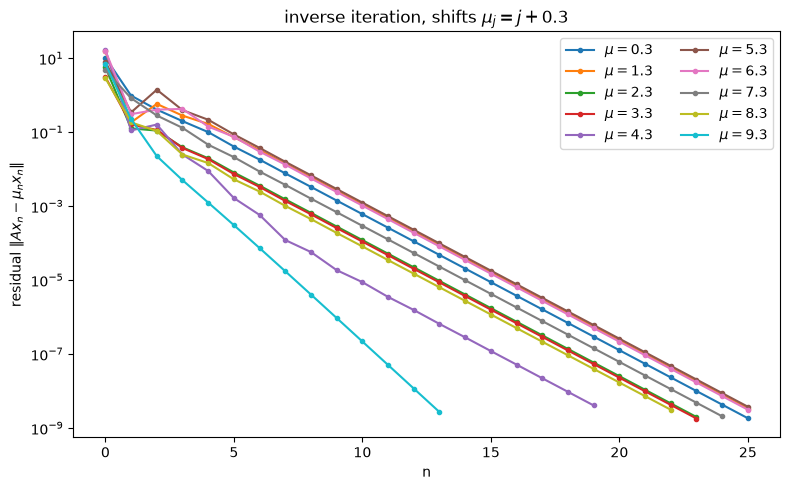

In [26]:
colors = plt.cm.tab10(np.arange(10))

plt.figure(figsize=(8, 5))
for j, hist in enumerate(hists):
    plt.semilogy(hist['res'], '.-', color=colors[j], label=rf'$\mu={j + 0.3:.1f}$')
plt.xlabel('n')
plt.ylabel(r'residual $\|Ax_n - \mu_n x_n\|$')
plt.title(r'inverse iteration, shifts $\mu_j = j + 0.3$')
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

---
c. Using the formula above:

$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$

we can get the rate of convergence. We need to raise the fraction to the power of $n$ and set it equal to the tolerance level of the method, which in our case is $10^{-10}$:

$$
\left(\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|}\right)^n = 10^{-10}.
$$

By transforming the formula we get

$$
n = \log_{\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|}} 10^{-10},
$$

where $n$ is the number of iterations.

We can take $\mu = 7$, then $\mu = 7.3$ and $\mu = 7.49$:

$$
\log_{\frac{|\lambda_* - 7.3|}{|\lambda_{**} - 7.3|}} 10^{-10} = \log_{3/7} 10^{-10} \approx 27.18 \;\Rightarrow\; n = 28, \quad
\log_{\frac{|\lambda_* - 7.49|}{|\lambda_{**} - 7.49|}} 10^{-10} = \log_{0.49/0.51} 10^{-10} \approx 575.6 \;\Rightarrow\; n = 576
$$

The closer $\mu$ is to $\lambda_*$, the smaller the rate becomes, so $n$ decreases.

---

mu=7.3: lambda=6.9999999986 (error 1.4e-09), sin_angle=3.3e-09, iterations=20
mu=7.49: lambda=7.0000000017 (error 1.7e-09), sin_angle=4.0e-09, iterations=424


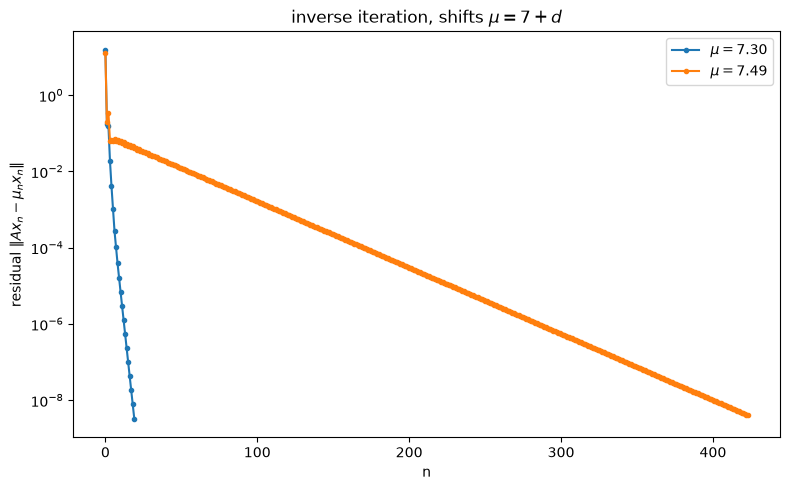

In [27]:
j = 7
offsets = [0.3, 0.49]
runs = {}

for d in offsets:
    mu = j + d
    lam, x, hist = inverse_iteration(A10, mu)
    runs[d] = hist
    print(f'mu={mu}: lambda={lam.real:.10f} (error {abs(lam - j):.1e}), '
          f'sin_angle={sin_angle(x, P10[:, j]):.1e}, iterations={len(hist["res"])}')

colors = plt.cm.tab10(np.arange(10))

plt.figure(figsize=(8, 5))
for i, (d, hist) in enumerate(runs.items()):
    plt.semilogy(hist['res'], '.-', color=colors[i], label=rf'$\mu={j + d:.2f}$')
plt.xlabel('n')
plt.ylabel(r'residual $\|Ax_n - \mu_n x_n\|$')
plt.title(rf'inverse iteration, shifts $\mu = {j} + d$')
plt.legend()
plt.tight_layout()
plt.show()

### 2.4 A shift that is *too* good
Take $\mu = 4 + 10^{-12}$. Compute $\kappa(A_{10} - \mu I)$ with `np.linalg.cond`. By everything you learned in Modules 1–2, solving with this matrix should be hopeless. Run `inverse_iteration` anyway and report the number of iterations and the accuracy of the eigenvector. Then explain, in your own words, why the huge condition number does no harm here. *(Hint: the solution $\mathbf{y}$ is badly wrong in length; in which direction is it wrong?)*

In [28]:
j = 4
mu = 4 + 1e-12
print(f'cond(A) = {np.linalg.cond(A10):.2e}')
print(f'cond(A - mu I) = {np.linalg.cond(A10 - mu * np.identity(10)):.2e}')

lam, x, hist = inverse_iteration(A10, mu)
print(f'j={j}: lambda = {lam.real:.10f} (error {abs(lam - j):.1e}), '
      f'sin_angle to P[:, {j}] = {sin_angle(x, P10[:, j]):.1e}, iterations: {len(hist["res"])}')
print('residuals:', hist['res'])

cond(A) = 4.53e+16
cond(A - mu I) = 1.18e+14
j=4: lambda = 4.0000000000 (error 8.4e-13), sin_angle to P[:, 4] = 1.8e-12, iterations: 2
residuals: [np.float64(5.866506539953177), np.float64(5.815248291594081e-13)]


---
cond ≈ 1e16, but inverse iteration converges in 2 iterations with sin_angle ~1e-12.

The shift makes A10 - mu*I nearly singular instead of singular. For mu = 4 exactly it would be singular, because (A10 - 4I)v4 = 0. Now (A10 - mu * I)v4 = -1e-12 * v4, so the matrix almost kills v4. That is where the huge condition number comes from. In practice, because of rounding errors, even mu = 4 gives a nearly singular matrix, not an exactly singular one, so it also works.

The huge cond does no harm because the exact solution y = (A10 - mu*I)^(-1) x contains the term c4/(4 - mu) * v4, and 1/(4 - mu) = 1e12. So y is about 1e12 * v4 plus small terms of size ~1, which are nothing next to it. The rounding error is amplified only in the direction that the matrix almost kills, and this is v4 again. So it only changes the length of y (say 1e12 or 1.3e12), but y still points almost exactly along v4.

We need only the direction of the eigenvector, and after y / ||y|| the length does not matter anyway. So the error that cond predicts is in the part of y that we throw away. For a usual system Ax = b it would be different, because there we need the whole solution, not only its direction.

---

---
## 3. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README` — an explained wall is worth more at the defence than a clean output you cannot explain.

---

Here I learned how to find eigenvalues efficiently, without ever forming huge matrices that would not fit in any computational system. The many edge cases where the method fails did not surprise me so much as they showed how many places there are where the system can break down. The case in 1.4.c with the matrix of condition number 10^3 also took time to understand, cause I could not see why the error never dropped below about 1e-13. The most unexpected case was 1.5.4, and I spent a lot of time on it as well. At least it was fun (and sometimes painful), but more importantly it was useful for understanding how eigenvalues work in practice.

---

---
# ★ Extensions
Do **at most one** extension for the whole lab (A1, A2 here, or B1 in the Core B notebook). The point is awarded for **a defended finding**: end your extension with a short paragraph headed *Finding* that states what you found and why.

## ★ A1. The QR algorithm: what `np.linalg.eig` builds on
Starting from $A_1 = A$, repeat: factor $A_k = Q_kR_k$, set $A_{k+1} := R_kQ_k$. Under mild assumptions $A_k$ tends to an upper-triangular matrix with the eigenvalues of $A$ on the diagonal.

1. Show that every $A_{k+1}$ is similar to $A_k$ (write $A_{k+1}$ as $Q_k^\top A_k Q_k$), so the eigenvalues never change.
2. Implement the **unshifted** method (`np.linalg.qr` is allowed). Stop when the largest entry below the diagonal is below $10^{-10}\|A\|_F$. Run it on $A = Q\,\mathrm{diag}(1,2,\dots,10)\,Q^\top$. Count the iterations. Predict that count from the ratios $\lambda_{i+1}/\lambda_i$ before you run it. *(Hint: the unshifted method behaves like power iteration on all columns at once.)*
3. Implement a **shifted** version with deflation: on the active $m\times m$ block, use $\mu = a_{mm}$, factor $A_k - \mu I = QR$, set $A_{k+1} = RQ + \mu I$; when $|a_{m,m-1}|$ is negligible, accept $a_{mm}$ and continue with the leading $(m-1)\times(m-1)$ block. Count the total iterations on the same $A$, and record $|a_{m,m-1}|$ step by step for one eigenvalue. How fast does it fall — do the correct digits roughly double, or more?
4. Run the unshifted method on a real matrix whose dominant eigenvalues are a complex pair. What does $A_k$ look like after many steps? Connect this with failure case 1 of §1.5.

In [29]:
# YOUR CODE HERE

## ★ A2. Stable, yet it grows: non-normal iterated maps
An iterated map $\mathbf{x}_{n+1} = A\mathbf{x}_n$ with spectral radius $\rho(A) < 1$ always tends to $\mathbf{0}$. It need **not** get there monotonically. This matters whenever a linear recurrence is called "stable" because its eigenvalues are inside the unit circle — a linear RNN or an autoregressive model, for example.

1. Take $A = \begin{pmatrix} 0.95 & 10 \\ 0 & 0.9\end{pmatrix}$. Plot $\|A^n\|_2$ for $n = 0,\dots,200$ together with $\rho(A)^n$ and the bound $\kappa(P)\,\rho(A)^n$ from Lecture 3.1 ($P$ the eigenvector matrix; here you may use `np.linalg.eig`). Find the peak of $\|A^n\|_2$ and the $n$ where it happens.
2. Derive $A^n$ in closed form for this triangular $A$ and use it to explain the peak.
3. Repeat for the $20\times20$ bidiagonal matrix with $0.9$ on the diagonal and $1$ on the superdiagonal. How large does $\|A^n\|_2$ get before it decays? Why is $\kappa(P)$ useless as a bound here?

In [30]:
# YOUR CODE HERE